# Réplica de un GP heterocedástico con optimización bayesiana

**Artículo:** White, G. M., Siegel, A. P., & Tovar, A. (2024). *Optimizing thermoplastic starch film with heteroscedastic Gaussian processes in Bayesian experimental design framework.* Materials, 17(21), 5345. https://doi.org/10.3390/ma17215345

**Datos originales:** https://github.com/andres-tovar-purdue/materials (GPL-3.0)

**Autor de la réplica:** Iván Eduardo Palti Flores · Curso: Propuesta de Investigación 2026-2 · Desarrollado con asistencia de Claude (Anthropic)

---

### Qué hace este cuaderno

Un cuaderno, de arriba abajo, con todo el flujo:

| Sección | Qué hace |
|---|---|
| 1 | Prepara el entorno |
| 2 | Carga los 5 CSV del artículo (uno por iteración) |
| 3 | Implementa el modelo (GP de la media + GP de la varianza), la mejora esperada (EI) y la propuesta de lote |
| 4 | **Réplica:** aplica el algoritmo a los datos y compara con las Tablas 1 y 2 del artículo |
| 5 | **Pruebas A a F:** desviación, sensibilidad del lote, validación prospectiva, leave-one-out, interpretabilidad y simulación |
| 6 | Figuras |
| 7 | Pruebas automáticas |
| 8 | Conclusiones y conexión con la tesis |

**Qué es y qué no es:** no se repiten los experimentos de laboratorio. Se verifica que el algoritmo, aplicado a los datos publicados, toma las mismas decisiones que los autores. Las pruebas A a F son extensiones propias.

**Ejecución:** `Kernel > Restart & Run All`. Tarda alrededor de un minuto. Requiere solo `numpy`, `scipy`, `pandas` y `matplotlib`.

## 1. Preparación del entorno

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.linalg import cho_factor, cho_solve
from scipy.stats import norm

os.makedirs('figuras', exist_ok=True)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

plt.rcParams.update({'font.size': 10.5, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlesize': 11.5, 'axes.titleweight': 'bold', 'figure.dpi': 110,
                     'axes.edgecolor': '#5a6872', 'axes.labelcolor': '#15212b', 'text.color': '#15212b',
                     'xtick.color': '#15212b', 'ytick.color': '#15212b'})

## 2. Datos

Cada CSV es el estado del experimento al **final de una iteración**: las filas son formulaciones ya medidas.

| Columna | Significado |
|---|---|
| `x1` | Plastificante (glicerol:vinagre), % p/p |
| `x2` | Almidón, % p/p |
| `y1mean`, `y1var` | Elongación a la rotura (EB, %): media y varianza de las réplicas |
| `y2mean`, `y2var` | Resistencia a la tracción (TS, MPa): media y varianza de las réplicas |

La iteración 1 tiene 9 experimentos y cada una de las siguientes agrega 5 o 6, hasta llegar a 30.

In [2]:
D = [pd.read_csv(f'data/tps_doe_{i}.csv') for i in range(1, 6)]
PROP = {'EB': ('y1mean', 'y1var'), 'TS': ('y2mean', 'y2var')}   # propiedad -> (columna de media, columna de varianza)
UN = {'EB': 'Elongación a la rotura, EB (%)', 'TS': 'Resistencia a la tracción, TS (MPa)'}

print('Experimentos acumulados por iteración:', [len(d) for d in D])
display(D[-1].round(3))

Experimentos acumulados por iteración: [9, 15, 20, 25, 30]


,x1,x2,y1mean,y1var,y2mean,y2var
0,0.5,5.0,6.775,5.355,1.416,0.144
1,1.0,5.0,9.372,5.480,1.372,0.146
2,1.5,5.0,12.378,5.554,1.269,0.153
3,0.5,7.0,10.525,4.971,2.767,0.258
4,1.0,7.0,16.327,5.100,2.571,0.253
5,1.5,7.0,23.896,5.183,2.287,0.252
6,0.5,9.0,6.073,3.935,2.004,0.565
7,1.0,9.0,6.027,4.019,1.496,0.540
8,1.5,9.0,6.802,4.088,1.245,0.519
9,0.5,2.0,31.113,4.898,0.534,0.021


## 3. El modelo

Para cada propiedad se entrenan **dos procesos gaussianos** (GP), ambos con kernel Matérn 3/2:

1. **GP de la media:** aprende `log(media)` en función de `(x1, x2)`, con un ruido pequeño fijo (1e-3).
2. **GP de la varianza:** aprende `log(varianza medida)`, es decir, cuánto ruido de laboratorio hay en cada zona. Por eso el modelo se llama *heterocedástico*.

Con esos dos modelos se calcula la **mejora esperada (EI)**, que mide cuánto se espera superar el mejor valor medido hasta ahora, y una **cota de confianza (LCB)** que empuja a explorar. El lote siguiente se arma con los puntos de EI y LCB de cada propiedad y las 4 esquinas de la región explorada, redondeados a pasos de 0.5.

Hay dos formas de calcular la incertidumbre predictiva σ:

- `mode='paper'`: replica el código publicado, que aplica `exp()` a las varianzas latentes de los GP.
- `mode='delta'`: propaga la incertidumbre del GP al espacio original con el método delta. La sección 5 muestra por qué conviene comparar ambas.

In [3]:
X1_MIN, X1_MAX, X2_MIN, X2_MAX = 0.5, 7.0, 0.5, 15.0   # región absoluta de exploración (paper)


def matern32(A, B, var, ls):
    d = np.sqrt(np.maximum(((A[:, None, :] / ls - B[None, :, :] / ls) ** 2).sum(-1), 0.0))
    s = np.sqrt(3.0) * d
    return var * (1.0 + s) * np.exp(-s)


class GP:
    """GP de media cero (como GPflow GPR por defecto), kernel Matérn 3/2.
    ls puede ser escalar (isotrópico, como el paper) o ARD (un valor por variable)."""

    def __init__(self, noise=None, ard=False, restarts=0, seed=0):
        self.fixed_noise, self.ard, self.restarts = noise, ard, restarts
        self.rng = np.random.default_rng(seed)

    def _unpack(self, p, d):
        var = np.exp(p[0])
        ls = np.exp(p[1:1 + (d if self.ard else 1)])
        ls = ls if self.ard else ls[0]
        noise = self.fixed_noise if self.fixed_noise is not None else np.exp(p[-1])
        return var, ls, noise

    def _nll(self, p, X, y):
        var, ls, noise = self._unpack(p, X.shape[1])
        K = matern32(X, X, var, ls) + (noise + 1e-9) * np.eye(len(X))
        try:
            c = cho_factor(K, lower=True)
        except np.linalg.LinAlgError:
            return 1e10
        a = cho_solve(c, y)
        return 0.5 * y @ a + np.log(np.diag(c[0])).sum() + 0.5 * len(y) * np.log(2 * np.pi)

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float).ravel()
        self.X, self.y = X, y
        d = X.shape[1]
        n_ls = d if self.ard else 1
        p0 = np.r_[0.0, np.zeros(n_ls)]                    # var=1, ls=1 (init de GPflow)
        if self.fixed_noise is None:
            p0 = np.r_[p0, 0.0]                            # ruido=1 (init de GPflow)
        starts = [p0] + [p0 + self.rng.normal(0, 1, len(p0)) for _ in range(self.restarts)]
        best = None
        for s in starts:
            r = minimize(self._nll, s, args=(X, y), method="L-BFGS-B",
                         bounds=[(-12, 12)] * len(s))
            if best is None or r.fun < best.fun:
                best = r
        self.p = best.x
        self.var, self.ls, self.noise = self._unpack(self.p, d)
        K = matern32(X, X, self.var, self.ls) + (self.noise + 1e-9) * np.eye(len(X))
        self.c = cho_factor(K, lower=True)
        self.alpha = cho_solve(self.c, y)
        return self

    def predict_f(self, Xs):
        Ks = matern32(np.asarray(Xs, float), self.X, self.var, self.ls)
        mu = Ks @ self.alpha
        v = cho_solve(self.c, Ks.T)
        var = self.var - (Ks * v.T).sum(1)
        return mu, np.maximum(var, 1e-12)


class HGP:
    """Un par (GP_media, GP_log-varianza) para una propiedad."""

    def __init__(self, ard=False, restarts=0):
        self.m = GP(noise=1e-3, ard=ard, restarts=restarts)
        self.v = GP(noise=None, ard=ard, restarts=restarts)

    def fit(self, X, mean, var):
        self.m.fit(X, np.log(mean))
        self.v.fit(X, np.log(var))
        return self

    def predict(self, Xs, mode="paper"):
        """Devuelve (media, desviación predictiva, componentes).
        mode='paper'  : replica el código publicado (exp de las varianzas latentes).
        mode='delta'  : propagación por método delta, en unidades originales."""
        mm, mv = self.m.predict_f(Xs)
        vm, vv = self.v.predict_f(Xs)
        mean = np.exp(mm)
        if mode == "paper":
            a, b, c = np.exp(mv), np.exp(vm), np.exp(vv)      # tal cual el cuaderno
            return mean, np.sqrt(a + b + c), (a, b, c)
        a = (mean ** 2) * mv                                   # incertidumbre de la media (delta)
        b = np.exp(vm + 0.5 * vv)                              # ruido esperado (lognormal)
        return mean, np.sqrt(a + b), (a, b, np.zeros_like(a))


def expected_improvement(y_best, mean, std):
    """EI para maximizar (equivale a la versión de minimizar del paper con signo cambiado)."""
    delta = mean - y_best
    z = delta / np.where(std > 0, std, 1)
    ei = delta * norm.cdf(z) + std * norm.pdf(z)
    return np.where(std > 0, ei, 0.0)


def round_half(x):
    return np.round(np.asarray(x) * 2) / 2


def explore_grid(x1, x2, scale=1.5, n=100):
    """Región de exploración: rango observado ampliado, recortado a la región absoluta."""
    x1min, x1max, x2min, x2max = x1.min(), x1.max(), x2.min(), x2.max()
    l1, l2 = x1max - x1min, x2max - x2min
    lb1 = round_half(max(X1_MIN, x1min - 0.5 * l1 * scale)); ub1 = round_half(min(X1_MAX, x1max + 0.5 * l1 * scale))
    lb2 = round_half(max(X2_MIN, x2min - 0.5 * l2 * scale)); ub2 = round_half(min(X2_MAX, x2max + 0.5 * l2 * scale))
    g1, g2 = np.meshgrid(np.linspace(lb1, ub1, n), np.linspace(lb2, ub2, n))
    return np.c_[g1.ravel(), g2.ravel()], (lb1, ub1, lb2, ub2)


def propose_batch(X, models, bests, grid, mode="paper"):
    """Propone el siguiente lote como el paper: EI + LCB por propiedad + 4 esquinas."""
    pts, info = [], {}
    for name, mdl in models.items():
        mean, std, _ = mdl.predict(grid, mode)
        ei = expected_improvement(bests[name], mean, std)
        i = int(np.argmax(ei)); p_ei = tuple(round_half(grid[i]))
        # LCB (versión "optimista" del paper): aumenta kappa hasta que el punto cambie
        p_lcb, kappa = p_ei, 0.0
        while p_lcb == p_ei and kappa < 2 ** 12:
            j = int(np.argmax(mean + kappa * std)); p_lcb = tuple(round_half(grid[j]))
            kappa = 2 ** kappa + 1 if name == "EB" else 2 ** kappa
        info[name] = dict(max_ei=float(ei[i]), p_ei=p_ei, p_lcb=p_lcb, std_at_ei=float(std[i]))
        pts += [p_ei, p_lcb]
    corners = [(grid[:, 0].min(), grid[:, 1].min()), (grid[:, 0].min(), grid[:, 1].max()),
               (grid[:, 0].max(), grid[:, 1].min()), (grid[:, 0].max(), grid[:, 1].max())]
    allp = sorted(set(pts + corners))
    have = {tuple(r) for r in X}
    new = [p for p in allp if not any(np.allclose(p, h) for h in have)]
    return new, info

## 4. Réplica del artículo

Para cada iteración *k* se entrena con los datos de `tps_doe_k.csv`, se calcula la mejora esperada máxima y se propone el siguiente lote. Después se compara con dos cosas que publica el artículo:

- **Tablas 1 y 2:** mejor valor por iteración y mejora esperada máxima.
- **Experimentos reales:** los puntos que aparecen en `tps_doe_(k+1).csv` y no estaban en `tps_doe_k.csv`.

In [4]:
PAPER_EI = {'EB': [6.06, 32.5, 2.97, 2.23, 3.16], 'TS': [0.615, 0.609, 0.605, 0.604, 0.604]}   # Tablas 1 y 2
PAPER_BEST = {'EB': [23.9, 69.8, 69.8, 69.8, 96.7], 'TS': [2.77] * 5}

rows, batches = [], []
for k, d in enumerate(D, 1):
    X = d[['x1', 'x2']].values
    mods = {p: HGP().fit(X, d[m].values, d[v].values) for p, (m, v) in PROP.items()}
    bests = {p: d[m].max() for p, (m, v) in PROP.items()}
    grid, _ = explore_grid(X[:, 0], X[:, 1])
    new, info = propose_batch(X, mods, bests, grid)
    for p, (m, v) in PROP.items():
        i = d[m].idxmax()
        _, std, _ = mods[p].predict(X[[i]])
        rows.append(dict(iter=k, prop=p, n_exp=len(d), x1_best=X[i, 0], x2_best=X[i, 1], y_best=d[m][i],
                         paper_y_best=PAPER_BEST[p][k - 1], max_ei_replica=info[p]['max_ei'], max_ei_paper=PAPER_EI[p][k - 1],
                         std_pred_best=float(std[0])))
    if k < 5:
        real = {tuple(r) for r in D[k][['x1', 'x2']].values} - {tuple(r) for r in X}
        batches.append(dict(iter=k, propuestos=len(new), reales=len(real), coinciden=len(set(new) & real)))

res = pd.DataFrame(rows)
bt = pd.DataFrame(batches)
print('Mejor valor y EI máxima por iteración: réplica frente a las Tablas 1 y 2')
display(res.round(3))
print('Lotes propuestos por el código frente a los experimentos reales')
display(bt)
print(f"Coincidencia total: {bt.coinciden.sum()} de {bt.reales.sum()} experimentos reales")

Mejor valor y EI máxima por iteración: réplica frente a las Tablas 1 y 2


,iter,prop,n_exp,x1_best,x2_best,y_best,paper_y_best,max_ei_replica,max_ei_paper,std_pred_best
0,1,EB,9,1.5,7.0,23.896,23.90,6.057,6.060,2.680
1,1,TS,9,0.5,7.0,2.767,2.77,0.615,0.615,1.503
2,2,EB,15,2.0,2.0,69.761,69.80,32.509,32.500,2.858
3,2,TS,15,0.5,7.0,2.767,2.77,0.609,0.609,1.544
4,3,EB,20,2.0,2.0,69.761,69.80,2.970,2.970,3.949
5,3,TS,20,0.5,7.0,2.767,2.77,0.605,0.605,1.541
6,4,EB,25,2.0,2.0,69.761,69.80,2.230,2.230,4.021
7,4,TS,25,0.5,7.0,2.767,2.77,0.604,0.604,1.541
8,5,EB,30,4.5,2.0,96.715,96.70,3.164,3.160,5.806
9,5,TS,30,0.5,7.0,2.767,2.77,0.604,0.604,1.541


Lotes propuestos por el código frente a los experimentos reales


,iter,propuestos,reales,coinciden
0,1,6,6,6
1,2,5,5,5
2,3,5,5,5
3,4,5,5,5


Coincidencia total: 21 de 21 experimentos reales


## 5. Pruebas sobre el modelo (extensiones propias)

| Prueba | Pregunta |
|---|---|
| **A** | ¿De dónde sale la "SD = 1.54 MPa" que reporta el artículo para TS? |
| **B** | ¿Cambian los lotes propuestos si la incertidumbre se calcula con el método delta? |
| **C** | Validación prospectiva: si se entrena con la iteración *k*, ¿qué tan bien se predice el lote *k+1*? |
| **D** | Leave-one-out sobre los 30 puntos finales |
| **E** | Interpretabilidad: escalas ARD, efectos principales e índices de Sobol |
| **F** | Simulación in silico: BO frente a lotes aleatorios |

In [5]:
# Ajusta, para una iteración, un HGP por propiedad
def fit(d, ard=False):
    X = d[['x1', 'x2']].values
    return {p: HGP(ard=ard).fit(X, d[m].values, d[v].values) for p, (m, v) in PROP.items()}

### A. Descomposición de la desviación predictiva

Se compara, en el mejor punto de cada iteración, la desviación **medida** (raíz de `y1var` o `y2var` en el CSV), la σ del código del artículo y la σ por método delta.

In [6]:
# ---------- A) descomposición de la desviación ----------
rowsA = []
for k, d in enumerate(D, 1):
    mods = fit(d)
    X = d[['x1', 'x2']].values
    for p, (m, v) in PROP.items():
        i = d[m].idxmax()
        mean, std, (a, b, c) = mods[p].predict(X[[i]])
        _, std_d, _ = mods[p].predict(X[[i]], 'delta')
        rowsA.append(dict(iter=k, prop=p, mejor=float(d[m][i]), sd_medida_csv=float(np.sqrt(d[v][i])),
                          sd_paper=float(std[0]), sd_delta=float(std_d[0]),
                          var_a_exp_varlatente_media=float(a[0]), var_b_ruido_pred=float(b[0]), var_c_exp_varlatente_var=float(c[0])))
A = pd.DataFrame(rowsA)

display(A.round(3))

,iter,prop,mejor,sd_medida_csv,sd_paper,sd_delta,var_a_exp_varlatente_media,var_b_ruido_pred,var_c_exp_varlatente_var
0,1,EB,23.896,2.277,2.680,2.391,1.001,5.183,1.000
1,1,TS,2.767,0.508,1.503,0.515,1.001,0.258,1.000
2,2,EB,69.761,3.067,2.858,3.327,1.001,6.136,1.030
3,2,TS,2.767,0.508,1.544,0.595,1.001,0.340,1.042
4,3,EB,69.761,3.067,3.949,4.304,1.001,13.564,1.027
5,3,TS,2.767,0.508,1.541,0.588,1.001,0.332,1.040
6,4,EB,69.761,3.067,4.021,4.338,1.001,14.148,1.022
7,4,TS,2.767,0.508,1.541,0.588,1.001,0.331,1.044
8,5,EB,96.715,5.667,5.806,6.470,1.001,31.651,1.062
9,5,TS,2.767,0.508,1.541,0.591,1.001,0.336,1.037


**Lectura.** Para TS, la σ del código del artículo vale 1.50 a 1.54 en todas las iteraciones, y coincide con la "SD = 1.51 y 1.54" de la Tabla 2 y del resumen. La desviación medida en el CSV en ese punto es 0.51. Dos de los tres términos del cálculo (`var_a` y `var_c`) valen casi exactamente 1, porque el artículo aplica `exp()` a varianzas latentes cercanas a cero. Eso fija un piso de σ ≈ √2 ≈ 1.41 sin importar los datos, y para una propiedad que va de 0.3 a 2.8 MPa es demasiado grande. Solo afecta la incertidumbre, no la media predicha.

### B. ¿Cambia el lote propuesto con otra σ?

Se repite la propuesta de lote con `mode='delta'` y se cuenta cuántos de los experimentos reales coinciden.

In [7]:
# ---------- B) lote propuesto con modo 'delta' ----------
rowsB = []
for k in range(1, 5):
    d = D[k - 1]; X = d[['x1', 'x2']].values
    mods = fit(d); bests = {p: d[m].max() for p, (m, v) in PROP.items()}
    grid, _ = explore_grid(X[:, 0], X[:, 1])
    real = {tuple(r) for r in D[k][['x1', 'x2']].values} - {tuple(r) for r in X}
    for mode in ('paper', 'delta'):
        new, _ = propose_batch(X, mods, bests, grid, mode)
        rowsB.append(dict(iter=k, modo=mode, propuestos=len(new), reales=len(real), coinciden=len(set(new) & real)))
B = pd.DataFrame(rowsB)

display(B)

,iter,modo,propuestos,reales,coinciden
0,1,paper,6,6,6
1,1,delta,7,6,6
2,2,paper,5,5,5
3,2,delta,6,5,5
4,3,paper,5,5,5
5,3,delta,5,5,3
6,4,paper,5,5,5
7,4,delta,5,5,3


Con σ por método delta, las iteraciones 1 y 2 siguen coincidiendo, pero en las 3 y 4 solo coinciden 3 de 5 puntos. La σ afecta qué experimentos elige la adquisición. Conviene confirmarlo con los autores antes de afirmarlo.

### C. Validación prospectiva

Se entrena con las iteraciones hasta *k* y se predicen los puntos que el laboratorio midió en la iteración *k+1*. Es la prueba más exigente, porque cada lote visita zonas nuevas. Se compara el HGP (con las dos formas de σ) con un GP homocedástico simple. La **cobertura** es la fracción de puntos observados dentro del intervalo del 95 %; debería estar cerca de 0.95.

In [8]:
# ---------- C) validación prospectiva ----------
def metrics(y, mu, lo, hi):
    y, mu = np.asarray(y), np.asarray(mu)
    ss = ((y - mu) ** 2).sum(); sst = ((y - y.mean()) ** 2).sum()
    return dict(RMSE=float(np.sqrt(((y - mu) ** 2).mean())), MAE=float(np.abs(y - mu).mean()),
                R2=float(1 - ss / sst) if sst > 0 else np.nan,
                cobertura95=float(((y >= lo) & (y <= hi)).mean()), ancho_medio=float((hi - lo).mean()))

def vanilla(d, p):
    X = d[['x1', 'x2']].values
    g = GP(noise=None).fit(X, np.log(d[PROP[p][0]].values))
    return g

def predict_vanilla(g, Xs):
    mu, v = g.predict_f(Xs); s = np.sqrt(v + g.noise)
    return np.exp(mu), np.exp(mu - 1.96 * s), np.exp(mu + 1.96 * s)

pred_rows, rowsC, rowsD = [], [], []
for k in range(1, 5):
    d = D[k - 1]; dn = D[k]
    Xo = d[['x1', 'x2']].values
    keys = {tuple(r) for r in Xo}
    new = dn[[tuple(r) not in keys for r in dn[['x1', 'x2']].values]]
    Xn = new[['x1', 'x2']].values
    mods = fit(d)
    for p, (m, v) in PROP.items():
        y = new[m].values
        for modo in ('paper', 'delta'):
            mu, sd, _ = mods[p].predict(Xn, modo)
            rowsC.append(dict(iter_entrenamiento=k, prop=p, modelo=f'HGP ({modo})', n=len(y),
                              **metrics(y, mu, mu - 1.96 * sd, mu + 1.96 * sd)))
            for a, b, c in zip(Xn, y, zip(mu, sd)):
                pred_rows.append(dict(iter=k, prop=p, modelo=f'HGP ({modo})', x1=a[0], x2=a[1], y=b, mu=c[0], sd=c[1]))
        g = vanilla(d, p); mu, lo, hi = predict_vanilla(g, Xn)
        rowsC.append(dict(iter_entrenamiento=k, prop=p, modelo='GP homocedástico', n=len(y), **metrics(y, mu, lo, hi)))
        for a, b, c in zip(Xn, y, mu):
            pred_rows.append(dict(iter=k, prop=p, modelo='GP homocedástico', x1=a[0], x2=a[1], y=b, mu=c, sd=np.nan))
C = pd.DataFrame(rowsC)
# agregado global (todos los puntos nuevos de las 4 iteraciones), recalculando intervalos
agg = []
for p, (m, v) in PROP.items():
    ys, store = [], {'HGP (paper)': ([], [], []), 'HGP (delta)': ([], [], []), 'GP homocedástico': ([], [], [])}
    for k in range(1, 5):
        d = D[k - 1]; dn = D[k]; Xo = d[['x1', 'x2']].values; keys = {tuple(r) for r in Xo}
        new = dn[[tuple(r) not in keys for r in dn[['x1', 'x2']].values]]; Xn = new[['x1', 'x2']].values
        mods = fit(d); ys += list(new[m].values)
        for modo in ('paper', 'delta'):
            mu, sd, _ = mods[p].predict(Xn, modo); s = store[f'HGP ({modo})']
            s[0].extend(mu); s[1].extend(mu - 1.96 * sd); s[2].extend(mu + 1.96 * sd)
        mu, lo, hi = predict_vanilla(vanilla(d, p), Xn); s = store['GP homocedástico']
        s[0].extend(mu); s[1].extend(lo); s[2].extend(hi)
    for name, (mu, lo, hi) in store.items():
        agg.append(dict(prop=p, modelo=name, n=len(ys), **metrics(ys, mu, np.array(lo), np.array(hi))))
Cagg = pd.DataFrame(agg)

display(Cagg.round(3))

,prop,modelo,n,RMSE,MAE,R2,cobertura95,ancho_medio
0,EB,HGP (paper),21,26.165,19.844,-0.324,0.238,19.238
1,EB,HGP (delta),21,26.165,19.844,-0.324,0.714,87.038
2,EB,GP homocedástico,21,25.180,18.266,-0.226,0.857,142.447
3,TS,HGP (paper),21,0.365,0.244,0.551,1.000,7.240
4,TS,HGP (delta),21,0.365,0.244,0.551,1.000,2.184
5,TS,GP homocedástico,21,0.361,0.242,0.562,0.952,1.683


Para EB, el R² es negativo: el modelo predice mal las zonas que todavía no ha visto. Con la σ del artículo, el intervalo del 95 % cubre solo el 24 % de los puntos de EB; con σ por método delta sube a 71 %, y el GP homocedástico simple llega a 86 % con intervalos mucho más anchos.

### D. Leave-one-out sobre los 30 puntos finales

Se quita un punto, se entrena con los 29 restantes y se predice el que se quitó. Se repite para cada punto.

In [9]:
# ---------- D) LOO sobre los 30 puntos finales ----------
dF = D[-1]; XF = dF[['x1', 'x2']].values; n = len(dF)
loo = {p: {k: [] for k in ('paper', 'delta', 'van')} for p in PROP}
for i in range(n):
    tr = np.arange(n) != i
    for p, (m, v) in PROP.items():
        h = HGP().fit(XF[tr], dF[m].values[tr], dF[v].values[tr])
        for modo in ('paper', 'delta'):
            mu, sd, _ = h.predict(XF[[i]], modo); loo[p][modo].append((mu[0], mu[0] - 1.96 * sd[0], mu[0] + 1.96 * sd[0]))
        g = GP(noise=None).fit(XF[tr], np.log(dF[m].values[tr])); mu, lo, hi = predict_vanilla(g, XF[[i]])
        loo[p]['van'].append((mu[0], lo[0], hi[0]))
loo_rows = []; loo_pts = []
for p, (m, v) in PROP.items():
    y = dF[m].values
    for key, name in (('paper', 'HGP (paper)'), ('delta', 'HGP (delta)'), ('van', 'GP homocedástico')):
        arr = np.array(loo[p][key]); loo_rows.append(dict(prop=p, modelo=name, n=n, **metrics(y, arr[:, 0], arr[:, 1], arr[:, 2])))
        for j in range(n): loo_pts.append(dict(prop=p, modelo=name, y=y[j], mu=arr[j, 0], lo=arr[j, 1], hi=arr[j, 2], x1=XF[j, 0], x2=XF[j, 1]))
Dloo = pd.DataFrame(loo_rows)

display(Dloo.round(3))

,prop,modelo,n,RMSE,MAE,R2,cobertura95,ancho_medio
0,EB,HGP (paper),30,9.155,5.410,0.840,0.800,15.273
1,EB,HGP (delta),30,9.155,5.410,0.840,0.967,42.698
2,EB,GP homocedástico,30,9.577,5.719,0.825,0.933,50.756
3,TS,HGP (paper),30,0.266,0.179,0.850,1.000,6.286
4,TS,HGP (delta),30,0.266,0.179,0.850,1.000,1.859
5,TS,GP homocedástico,30,0.260,0.177,0.857,0.933,1.146


Dentro de la zona explorada, el modelo funciona bien (R² ≈ 0.84 y 0.85). Con la σ del artículo, el intervalo de TS tiene 6.3 MPa de ancho, sobre una propiedad que va de 0.3 a 2.8, así que cubre el 100 % pero no informa. Con σ por método delta el ancho baja a 1.9.

### E. Interpretabilidad

Con el modelo final (30 puntos) se calculan tres cosas:

- **Escalas de longitud ARD:** una por variable. Una escala corta significa que la propiedad cambia rápido con esa variable.
- **Efectos principales:** promedio de la predicción sobre el otro factor.
- **Índices de Sobol de primer orden:** fracción de la varianza de la media predicha que explica cada factor sola. Lo que sobra es interacción.

In [10]:
# ---------- E) interpretabilidad ----------
g1, g2 = np.meshgrid(np.linspace(X1_MIN, X1_MAX, 66), np.linspace(X2_MIN, X2_MAX, 117))  # paso 0.1 aprox.
G = np.c_[g1.ravel(), g2.ravel()]; shp = g1.shape
modsF = fit(dF); modsA = fit(dF, ard=True)
rowsE, grids = [], {}
for p in PROP:
    mean, sd, _ = modsF[p].predict(G); Z = mean.reshape(shp)           # filas = starch (x2), cols = plasticizer (x1)
    grids[p] = Z
    f1 = Z.mean(0); f2 = Z.mean(1); V = Z.var()
    S1 = f1.var() / V; S2 = f2.var() / V
    la = modsA[p].m.ls
    rowsE.append(dict(prop=p, S1_plastificante=S1, S2_almidon=S2, interaccion=1 - S1 - S2,
                      ls_iso=modsF[p].m.ls, ls_ARD_plastificante=la[0], ls_ARD_almidon=la[1]))
E = pd.DataFrame(rowsE)

display(E.round(3))

,prop,S1_plastificante,S2_almidon,interaccion,ls_iso,ls_ARD_plastificante,ls_ARD_almidon
0,EB,0.364,0.539,0.097,6.489,9.013,5.360
1,TS,0.264,0.394,0.343,1.900,3.390,1.225


### F. Simulación in silico: BO frente a lotes aleatorios

Se usa el modelo final como "verdad", se parte del diseño inicial de 9 puntos y se repite el ciclo 4 veces. El BO usa el algoritmo del artículo. Como referencia, 200 corridas con lotes del mismo tamaño elegidos al azar en la misma región.

**Advertencia:** la "verdad" se ajustó con puntos que el BO ya había elegido, así que es una ilustración, no una prueba concluyente.

In [11]:
# ---------- F) simulación in silico ----------
truth_m = {p: modsF[p] for p in PROP}
def truth(X):
    out = {}
    for p in PROP:
        mean, _, (a, b, c) = truth_m[p].predict(X); out[p] = (mean, np.exp(truth_m[p].v.predict_f(X)[0]))
    return out
pool1 = np.arange(X1_MIN, X1_MAX + .01, .5); pool2 = np.arange(X2_MIN, X2_MAX + .01, .5)
POOL = np.array([(a, b) for a in pool1 for b in pool2])
tp = truth(POOL); best_true = {p: tp[p][0].max() for p in PROP}

def simulate(strategy, seed=0, iters=4, counts=None):
    rng = np.random.default_rng(seed)
    X = D[0][['x1', 'x2']].values.copy()
    t = truth(X); Y = {p: t[p][0].copy() for p in PROP}; V = {p: t[p][1].copy() for p in PROP}
    hist = [{p: Y[p].max() for p in PROP}]; used = []
    for it in range(iters):
        if strategy == 'bo':
            mods = {p: HGP().fit(X, Y[p], V[p]) for p in PROP}
            grid, _ = explore_grid(X[:, 0], X[:, 1])
            new, _ = propose_batch(X, mods, {p: Y[p].max() for p in PROP}, grid)
            new = np.array(new) if new else np.empty((0, 2))
        else:
            idx = rng.choice(len(POOL), size=counts[it], replace=False); new = POOL[idx]
        used.append(len(new))
        if len(new):
            t = truth(new)
            X = np.vstack([X, new])
            for p in PROP: Y[p] = np.r_[Y[p], t[p][0]]; V[p] = np.r_[V[p], t[p][1]]
        hist.append({p: Y[p].max() for p in PROP})
    return (hist, used) if strategy == 'bo' else hist

hb, counts = simulate('bo')
hr = [simulate('rand', s, counts=counts) for s in range(200)]
rowsF = []
for it in range(5):
    for p in PROP:
        r = np.array([h[it][p] for h in hr])
        rowsF.append(dict(iter=it, n_exp=9 + sum(counts[:it]), prop=p, bo=hb[it][p] / best_true[p], rand_media=r.mean() / best_true[p],
                          rand_p10=np.percentile(r, 10) / best_true[p], rand_p90=np.percentile(r, 90) / best_true[p],
                          rand_prob_optimo=float((np.array(r) >= best_true[p] * 0.999).mean())))
F = pd.DataFrame(rowsF)

display(F.round(3))

,iter,n_exp,prop,bo,rand_media,rand_p10,rand_p90,rand_prob_optimo
0,0,9,EB,0.243,0.243,0.243,0.243,0.000
1,0,9,TS,1.000,1.000,1.000,1.000,1.000
2,1,15,EB,0.697,0.672,0.446,0.908,0.000
3,1,15,TS,1.000,1.000,1.000,1.000,1.000
4,2,19,EB,0.697,0.724,0.531,0.916,0.000
5,2,19,TS,1.000,1.000,1.000,1.000,1.000
6,3,24,EB,0.762,0.779,0.591,0.937,0.015
7,3,24,TS,1.000,1.000,1.000,1.000,1.000
8,4,29,EB,0.937,0.813,0.638,0.974,0.025
9,4,29,TS,1.000,1.000,1.000,1.000,1.000


## 6. Figuras

### Figura 1. Réplica frente al artículo

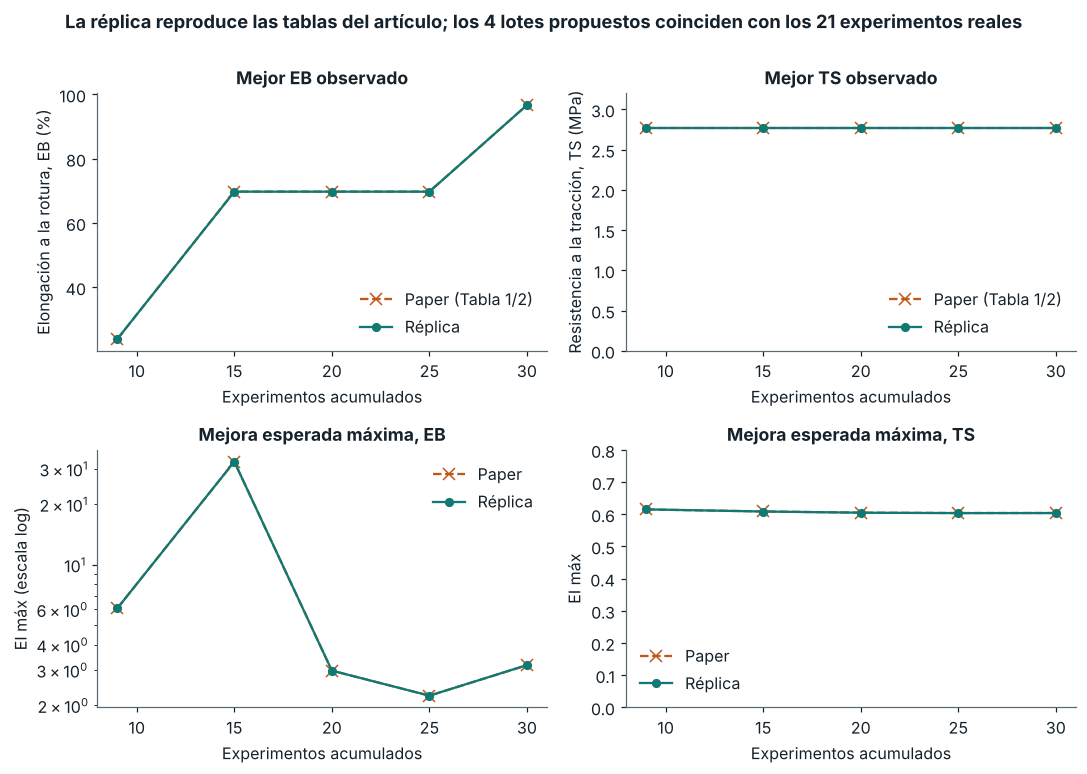

In [12]:
TEAL, ORG, SLATE = '#0f7a73', '#c2571a', '#5a6872'
R = res
# ---------- Fig 1: réplica vs paper ----------
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for j, p in enumerate(['EB', 'TS']):
    r = R[R['prop'] == p]
    a = ax[0, j]
    a.plot(r.n_exp, r.paper_y_best, 'x--', color=ORG, label='Paper (Tabla 1/2)', ms=8)
    a.plot(r.n_exp, r.y_best, 'o-', color=TEAL, label='Réplica', ms=5)
    a.set_title(f'Mejor {p} observado'); a.set_xlabel('Experimentos acumulados'); a.set_ylabel(UN[p]); a.legend(frameon=False, loc='lower right')
    if p == 'TS': a.set_ylim(0, 3.2)
    b = ax[1, j]
    b.plot(r.n_exp, r.max_ei_paper, 'x--', color=ORG, ms=8, label='Paper'); b.plot(r.n_exp, r.max_ei_replica, 'o-', color=TEAL, ms=5, label='Réplica')
    b.set_title(f'Mejora esperada máxima, {p}'); b.set_xlabel('Experimentos acumulados'); b.set_ylabel('EI máx')
    if p == 'EB': b.set_yscale('log'); b.set_ylabel('EI máx (escala log)')
    else: b.set_ylim(0, 0.8)
    b.legend(frameon=False)
fig.suptitle('La réplica reproduce las tablas del artículo; los 4 lotes propuestos coinciden con los 21 experimentos reales', fontsize=12, fontweight='bold', y=1.0)
fig.tight_layout(); fig.savefig('figuras/fig1_replica.png', bbox_inches='tight'); plt.show()

### Figura 2. Mapas del modelo final

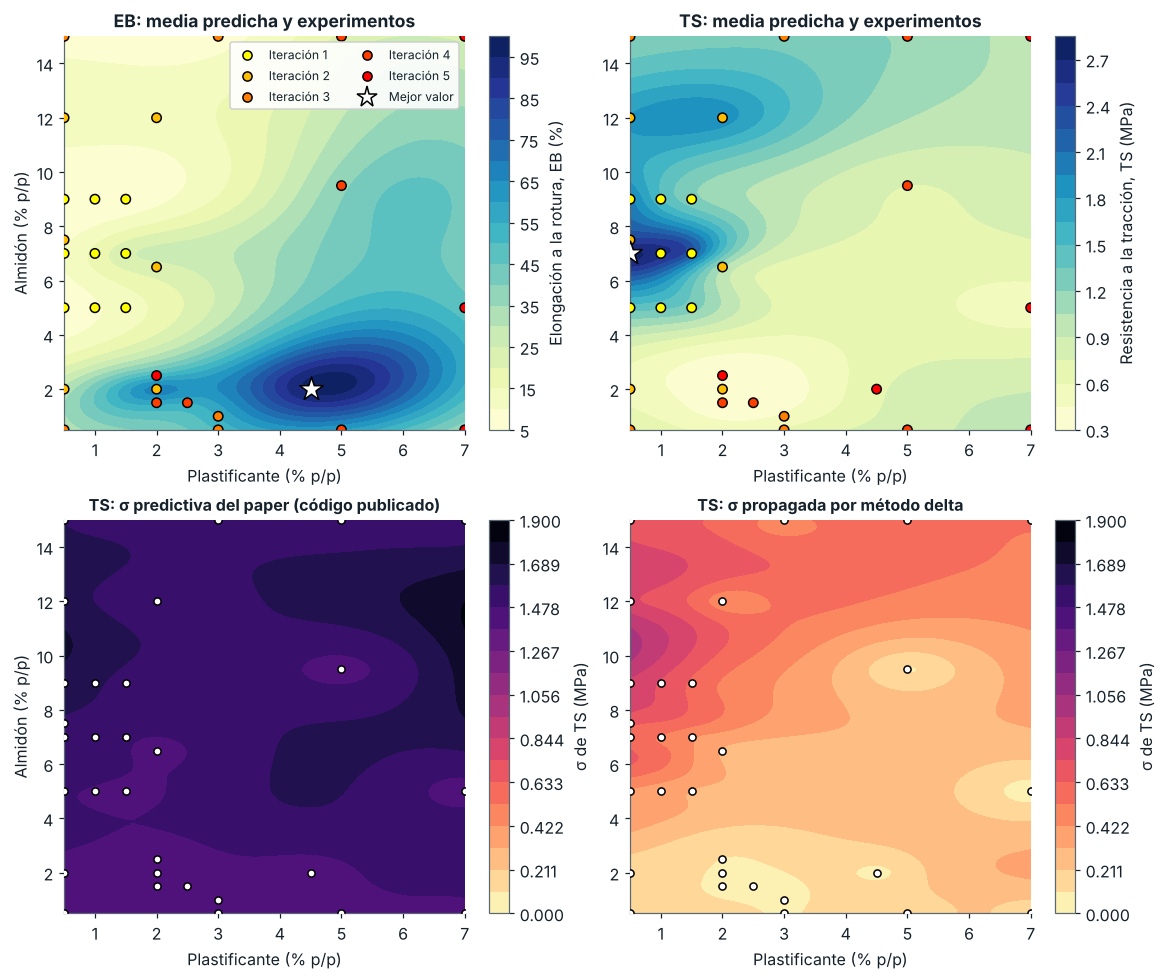

In [13]:
dF = D[-1]; XF = dF[['x1', 'x2']].values
mods = {p: HGP().fit(XF, dF[m].values, dF[v].values) for p, (m, v) in PROP.items()}
# ---------- Fig 2: mapas con el modelo final ----------
dF = D[-1]; XF = dF[['x1', 'x2']].values
mods = {p: HGP().fit(XF, dF[m].values, dF[v].values) for p, (m, v) in PROP.items()}
g1, g2 = np.meshgrid(np.linspace(X1_MIN, X1_MAX, 80), np.linspace(X2_MIN, X2_MAX, 120)); G = np.c_[g1.ravel(), g2.ravel()]
it_of = np.repeat(np.arange(1, 6), [9, 6, 5, 5, 5])
fig, ax = plt.subplots(2, 2, figsize=(10.5, 8.8), constrained_layout=True)
from matplotlib.lines import Line2D
for j, p in enumerate(['EB', 'TS']):
    mean, sd, _ = mods[p].predict(G)
    a = ax[0, j]; im = a.contourf(g1, g2, mean.reshape(g1.shape), 18, cmap='YlGnBu'); plt.colorbar(im, ax=a, label=UN[p])
    sc = a.scatter(XF[:, 0], XF[:, 1], c=it_of, cmap='autumn_r', vmin=1, vmax=5, edgecolor='k', s=38, zorder=3)
    i = dF[PROP[p][0]].idxmax(); a.scatter(*XF[i], marker='*', s=260, color='white', edgecolor='k', zorder=4)
    a.set_title(f'{p}: media predicha y experimentos'); a.set_xlabel('Plastificante (% p/p)'); a.set_ylabel('Almidón (% p/p)' if j == 0 else '')
hs = [Line2D([], [], marker='o', ls='', mfc=plt.cm.autumn_r((k - 1) / 4), mec='k', label=f'Iteración {k}') for k in range(1, 6)] + [Line2D([], [], marker='*', ls='', mfc='white', mec='k', ms=14, label='Mejor valor')]
ax[0, 0].legend(handles=hs, loc='upper right', fontsize=8, frameon=True, framealpha=.9, ncol=2)
mean, sd_p, _ = mods['TS'].predict(G); _, sd_d, _ = mods['TS'].predict(G, 'delta')
vmax = float(np.ceil(sd_p.max() * 10) / 10)
for j, (s, t) in enumerate(((sd_p, 'σ predictiva del paper (código publicado)'), (sd_d, 'σ propagada por método delta'))):
    a = ax[1, j]; im = a.contourf(g1, g2, s.reshape(g1.shape), np.linspace(0, vmax, 19), cmap='magma_r', vmin=0, vmax=vmax); plt.colorbar(im, ax=a, label='σ de TS (MPa)')
    a.scatter(XF[:, 0], XF[:, 1], c='white', edgecolor='k', s=22, zorder=3); a.set_title(f'TS: {t}', fontsize=10.5)
    a.set_xlabel('Plastificante (% p/p)'); a.set_ylabel('Almidón (% p/p)' if j == 0 else '')
fig.savefig('figuras/fig2_mapas.png'); plt.show()

### Figura 3. Interpretabilidad

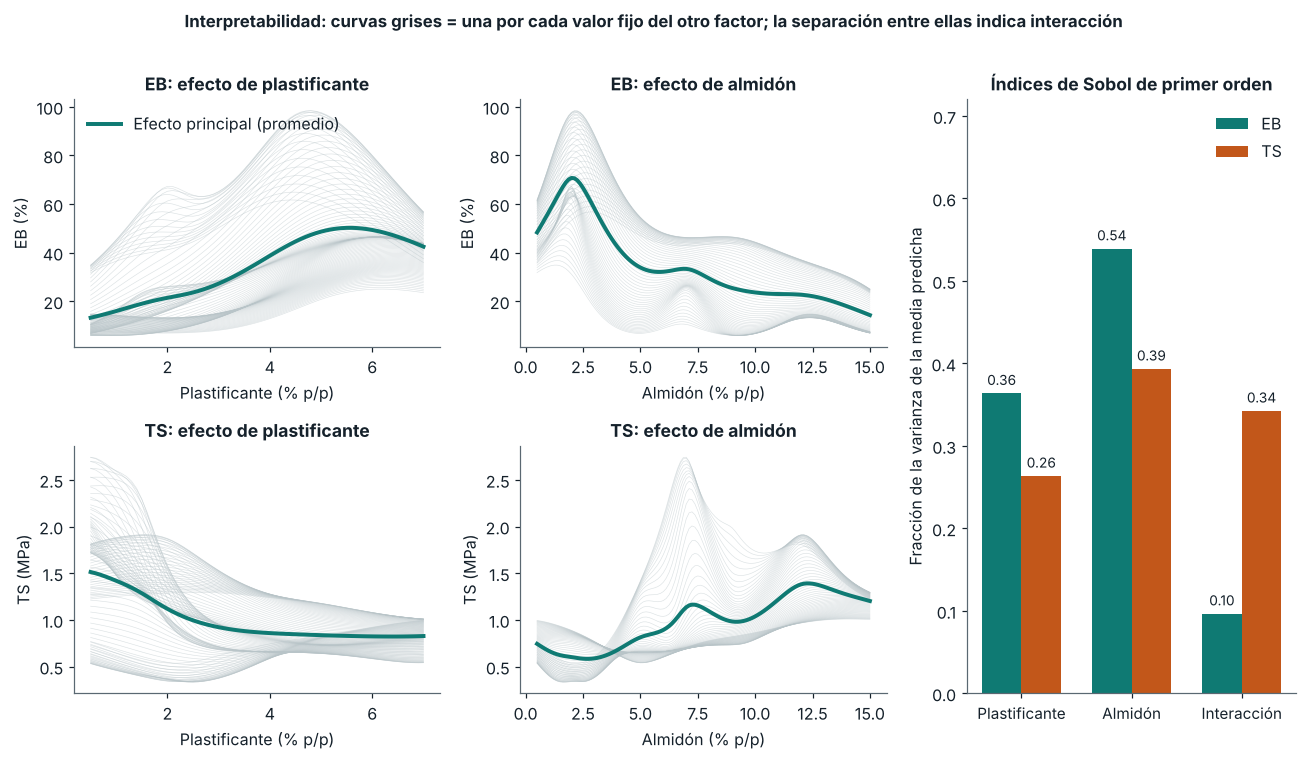

In [14]:
# ---------- Fig 3: interpretabilidad ----------
gx1, gx2 = np.meshgrid(np.linspace(X1_MIN, X1_MAX, 66), np.linspace(X2_MIN, X2_MAX, 117)); GG = np.c_[gx1.ravel(), gx2.ravel()]
fig = plt.figure(figsize=(12, 6.8)); gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.9])
for r_i, p in enumerate(['EB', 'TS']):
    Z = mods[p].predict(GG)[0].reshape(gx1.shape)       # filas: almidón, columnas: plastificante
    for c_i, (axis, xs, lab) in enumerate(((0, gx1[0], 'Plastificante (% p/p)'), (1, gx2[:, 0], 'Almidón (% p/p)'))):
        a = fig.add_subplot(gs[r_i, c_i])
        ICE = Z if axis == 0 else Z.T                    # cada fila = curva con el otro factor fijo
        a.plot(xs, ICE.T if axis == 0 else ICE.T, color='#b8c4c8', lw=0.4, alpha=0.5)
        a.plot(xs, ICE.mean(0) if axis == 0 else ICE.mean(0), color=TEAL, lw=2.6, label='Efecto principal (promedio)')
        a.set_xlabel(lab); a.set_ylabel(UN[p].split(',')[1].strip() if r_i == 0 else 'TS (MPa)')
        a.set_title(f'{p}: efecto de {lab.split(" (")[0].lower()}')
        if r_i == 0 and c_i == 0: a.legend(frameon=False, loc='upper left')
b = fig.add_subplot(gs[:, 2]); e = E.set_index('prop')
w = 0.36; xs = np.arange(3)
for k, p in enumerate(['EB', 'TS']):
    vals = [e.loc[p, 'S1_plastificante'], e.loc[p, 'S2_almidon'], e.loc[p, 'interaccion']]
    bars = b.bar(xs + (k - .5) * w, vals, w, color=[TEAL, ORG][k], label=p)
    for xx, v in zip(xs + (k - .5) * w, vals): b.text(xx, v + .01, f'{v:.2f}', ha='center', fontsize=9)
b.set_xticks(xs); b.set_xticklabels(['Plastificante', 'Almidón', 'Interacción'], fontsize=10); b.set_ylabel('Fracción de la varianza de la media predicha'); b.set_ylim(0, .72)
b.set_title('Índices de Sobol de primer orden'); b.legend(frameon=False)
fig.suptitle('Interpretabilidad: curvas grises = una por cada valor fijo del otro factor; la separación entre ellas indica interacción', fontsize=11, fontweight='bold', y=1.01)
fig.tight_layout(); fig.savefig('figuras/fig3_interpretabilidad.png', bbox_inches='tight'); plt.show()

### Figura 4. Validación

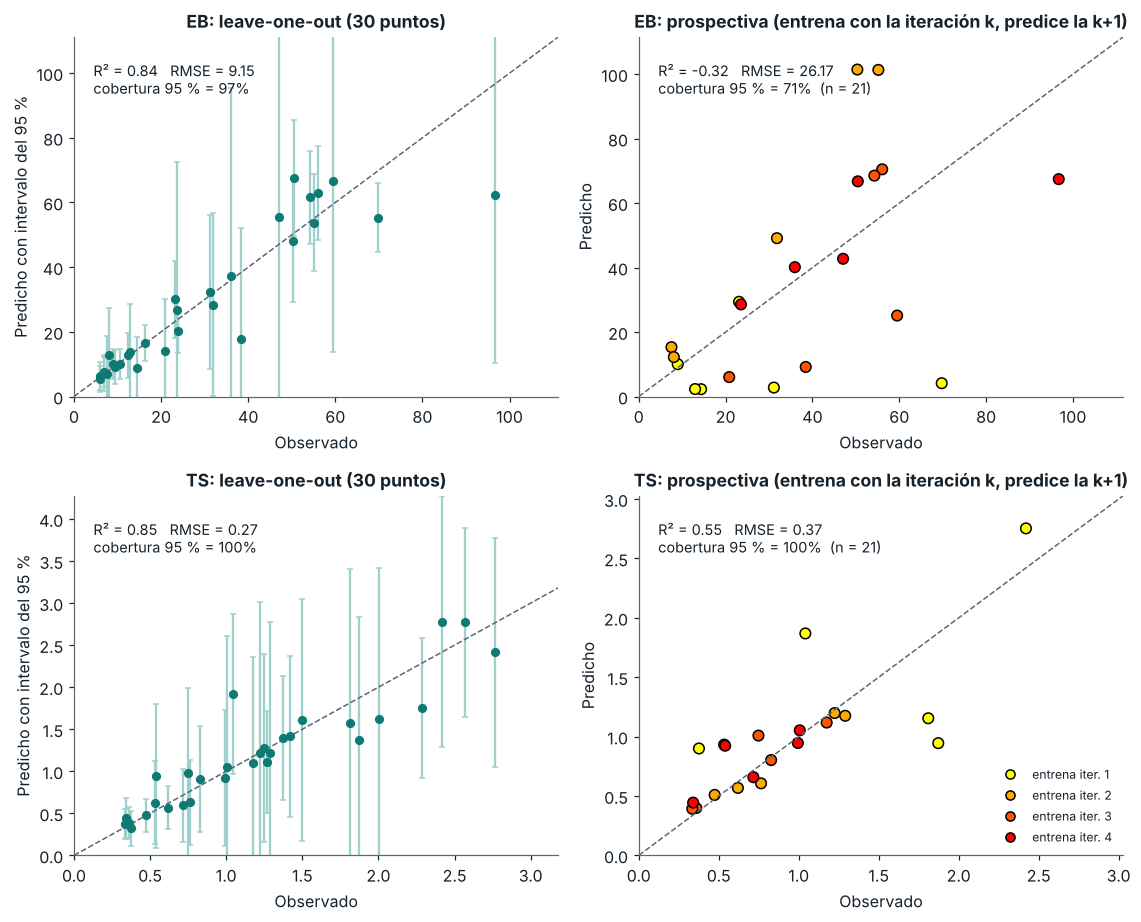

In [15]:
# ---------- Fig 4: validación ----------
L = pd.DataFrame(loo_pts); Pp = pd.DataFrame(pred_rows)
Dl = Dloo; Cg = Cagg
fig, ax = plt.subplots(2, 2, figsize=(10.5, 8.5))
for r_i, p in enumerate(['EB', 'TS']):
    l = L[(L['prop'] == p) & (L.modelo == 'HGP (delta)')]
    a = ax[r_i, 0]; mx = max(l.y.max(), l.hi.max() if p == 'TS' else l.mu.max()) * 1.05
    a.errorbar(l.y, l.mu, yerr=[l.mu - l.lo, l.hi - l.mu], fmt='o', color=TEAL, ecolor='#9fd0cc', ms=5, capsize=2)
    lim = [0, l.y.max() * 1.15]; a.plot(lim, lim, '--', color=SLATE, lw=1); a.set_xlim(lim); a.set_ylim(0 if p == 'EB' else 0, max(l.hi.max(), lim[1]) if p == 'TS' else lim[1] * 1.0)
    d = Dl[(Dl['prop'] == p) & (Dl.modelo == 'HGP (delta)')].iloc[0]
    a.set_title(f'{p}: leave-one-out (30 puntos)'); a.set_xlabel('Observado'); a.set_ylabel('Predicho con intervalo del 95 %')
    a.text(.04, .93, f'R² = {d.R2:.2f}   RMSE = {d.RMSE:.2f}\ncobertura 95 % = {d.cobertura95:.0%}', transform=a.transAxes, va='top', fontsize=9.5)
    q = Pp[(Pp['prop'] == p) & (Pp.modelo == 'HGP (delta)')]
    a = ax[r_i, 1]; cs = plt.cm.autumn_r((q['iter'] - 1) / 3)
    a.scatter(q.y, q.mu, c=cs, edgecolor='k', s=48)
    lim = [0, max(q.y.max(), q.mu.max()) * 1.1]; a.plot(lim, lim, '--', color=SLATE, lw=1); a.set_xlim(lim); a.set_ylim(lim)
    d = Cg[(Cg['prop'] == p) & (Cg.modelo == 'HGP (delta)')].iloc[0]
    a.set_title(f'{p}: prospectiva (entrena con la iteración k, predice la k+1)'); a.set_xlabel('Observado'); a.set_ylabel('Predicho')
    a.text(.04, .93, f'R² = {d.R2:.2f}   RMSE = {d.RMSE:.2f}\ncobertura 95 % = {d.cobertura95:.0%}  (n = {int(d.n)})', transform=a.transAxes, va='top', fontsize=9.5)
    if r_i == 1:
        from matplotlib.lines import Line2D
        a.legend(handles=[Line2D([], [], marker='o', ls='', mfc=plt.cm.autumn_r((k - 1) / 3), mec='k', label=f'entrena iter. {k}') for k in range(1, 5)], loc='lower right', fontsize=8, frameon=False)
fig.tight_layout(); fig.savefig('figuras/fig4_validacion.png', bbox_inches='tight'); plt.show()

### Figura 5. Simulación in silico

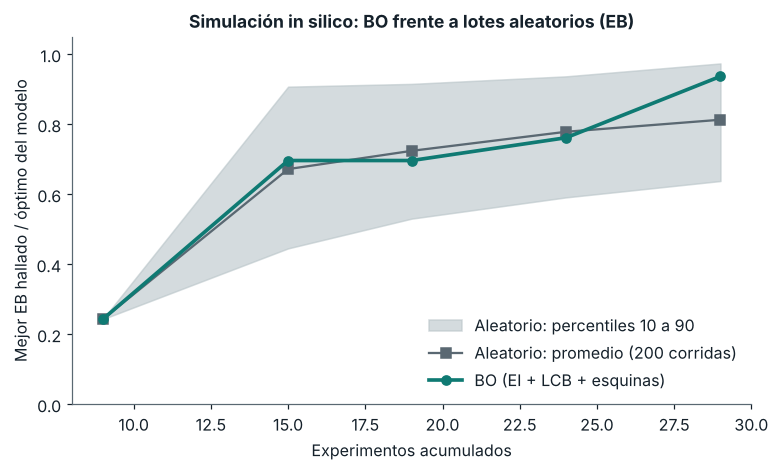

In [16]:
# ---------- Fig 5: simulación ----------
f = F[F['prop'] == 'EB']
fig, a = plt.subplots(figsize=(7.2, 4.4))
a.fill_between(f.n_exp, f.rand_p10, f.rand_p90, color='#b8c4c8', alpha=.6, label='Aleatorio: percentiles 10 a 90')
a.plot(f.n_exp, f.rand_media, 's-', color=SLATE, label='Aleatorio: promedio (200 corridas)')
a.plot(f.n_exp, f.bo, 'o-', color=TEAL, lw=2.4, label='BO (EI + LCB + esquinas)')
a.set_xlabel('Experimentos acumulados'); a.set_ylabel('Mejor EB hallado / óptimo del modelo'); a.set_ylim(0, 1.05)
a.set_title('Simulación in silico: BO frente a lotes aleatorios (EB)'); a.legend(frameon=False, loc='lower right')
fig.tight_layout(); fig.savefig('figuras/fig5_simulacion.png', bbox_inches='tight'); plt.show()

## 7. Pruebas automáticas

Cuatro comprobaciones que fallan con un `AssertionError` si la réplica se aparta del artículo.

In [17]:
def _fit(d):
    X = d[['x1', 'x2']].values
    return X, {p: HGP().fit(X, d[m].values, d[v].values) for p, (m, v) in PROP.items()}

def test_ei_coincide_con_tablas_del_paper():
    for k, d in enumerate(D):
        X, mods = _fit(d)
        grid, _ = explore_grid(X[:, 0], X[:, 1])
        for p, (m, _) in PROP.items():
            mean, std, _ = mods[p].predict(grid)
            ei = expected_improvement(d[m].max(), mean, std).max()
            assert abs(ei - PAPER_EI[p][k]) / PAPER_EI[p][k] < 0.02, (k + 1, p, ei)

def test_lotes_propuestos_son_los_experimentos_reales():
    for k in range(4):
        X, mods = _fit(D[k])
        bests = {p: D[k][m].max() for p, (m, _) in PROP.items()}
        grid, _ = explore_grid(X[:, 0], X[:, 1])
        new, _ = propose_batch(X, mods, bests, grid)
        real = {tuple(r) for r in D[k + 1][['x1', 'x2']].values} - {tuple(r) for r in X}
        assert set(new) == real, (k + 1, sorted(set(new) ^ real))

def test_optimos_finales():
    d = D[-1]
    i = d.y1mean.idxmax(); assert (d.x1[i], d.x2[i]) == (4.5, 2.0) and abs(d.y1mean[i] - 96.7) < 0.1
    i = d.y2mean.idxmax(); assert (d.x1[i], d.x2[i]) == (0.5, 7.0) and abs(d.y2mean[i] - 2.77) < 0.01

def test_sd_del_paper_para_ts_es_artefacto_de_la_formula():
    d = D[1]; X, mods = _fit(d); i = d.y2mean.idxmax()
    _, sd_paper, _ = mods['TS'].predict(X[[i]])
    _, sd_delta, _ = mods['TS'].predict(X[[i]], 'delta')
    assert abs(sd_paper[0] - 1.54) < 0.02          # lo que reporta el artículo
    assert abs(np.sqrt(d.y2var[i]) - 0.51) < 0.01   # SD medida en el CSV
    assert sd_delta[0] < 0.7                        # con propagación delta queda cerca de lo medido

for name, fn in list(globals().items()):
    if name.startswith('test_'):
        fn(); print('OK ', name)

OK  test_ei_coincide_con_tablas_del_paper
OK  test_lotes_propuestos_son_los_experimentos_reales
OK  test_optimos_finales
OK  test_sd_del_paper_para_ts_es_artefacto_de_la_formula


## 8. Conclusiones y conexión con la tesis

**Réplica.** El código propone los mismos experimentos que hicieron los autores (21 de 21 en las iteraciones 1 a 4) y reproduce sus tablas de mejora esperada. Óptimos: **EB = 96.7 %** con 4.5 % de plastificante y 2.0 % de almidón; **TS = 2.77 MPa** con 0.5 % de plastificante y 7.0 % de almidón. El óptimo de TS ya estaba en el diseño inicial.

**Hallazgo.** La "SD = 1.54 MPa" del resumen coincide con la σ del modelo, no con la desviación medida (0.51 MPa). Se debe a un `exp()` en el cálculo de la incertidumbre. Afecta a la incertidumbre y puede cambiar qué puntos elige la adquisición; conviene confirmarlo con los autores.

**Validación.** Leave-one-out: R² = 0.84 (EB) y 0.85 (TS). Prospectiva: R² = −0.32 (EB) y 0.55 (TS). Interpola bien y extrapola mal.

**Interpretabilidad.** Para ambas propiedades pesa más el almidón (Sobol 0.54 en EB y 0.39 en TS). En TS la interacción pesa 0.34. Los óptimos de EB y TS están en esquinas opuestas del espacio, lo que sugiere un tratamiento multiobjetivo.

**Qué se hereda para la tesis (dataset de películas de CMF de cítricos).**
- Un GP por propiedad con la desviación de cada formulación como ruido.
- EI y LCB para proponer lotes, con puntos de control y esquinas.
- σ por método delta y verificación de la cobertura del 95 % antes de confiar en los intervalos.
- Cambia: hay una variable categórica (fruta) y una binaria (pectina), además del % de celulosa.

**Limitaciones.** Es una reimplementación del algoritmo, no una repetición de los experimentos. Los CSV traen la media y la varianza por formulación, no las mediciones por probeta. Las pruebas A a F son extensiones propias y la simulación F usa como "verdad" un modelo ajustado con puntos elegidos por BO.